# B-6511502A · o ciclo de retreino com uma mudança simulada

Não temos dado do B-6511502A depois de 05/2023, então não dá para saber se o "normal" dele mudou. Para deixar a
pipeline pronta e testada, simulamos o que aconteceu no B-8802B depois do reparo: **a partir de 01/11/2022 o dado real
recebe uma mudança permanente** (só com a bomba operando) e o ciclo roda como se fosse produção.

1. **A falha real de 15/05/2023** com o modelo em produção (sem mudança nenhuma).
2. **As três mudanças simuladas** — temperatura, vibração e regime de operação.
3. **O que acontece sem retreino** — o modelo atual diante de cada mudança.
4. **O ciclo de retreino** — monitor, modelos de 1, 3 e 6 meses (12 não cabem: o dado acaba em 05/2023).
5. **A falha real com os modelos retreinados** — eles ainda detectam?

> Este teste prova que o **processo** funciona no B-6511502A. Ele não diz se o modelo está bom **hoje**: isso só os
> dados de 2024–26 mostram.

In [1]:
import sys
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, matplotlib.dates as mdates
%config InlineBackend.figure_format = "retina"
RAIZ = Path.cwd().resolve()
while not (RAIZ / "scripts").exists(): RAIZ = RAIZ.parent
sys.path.insert(0, str(RAIZ / "scripts")); sys.path.insert(0, str(RAIZ / "src"))
import drift_simulado_b6511502a as ds
R = RAIZ / "results/drift_simulado_b6511502a"
etapas = pd.read_csv(R / "etapas.csv"); cands = pd.read_csv(R / "candidatos.csv")
raw0 = ds.load_equipment_data(ds.EQ)
MUD, FALHA = ds.MUDANCA, ds.FALHA
VERMELHO, SERIE, TEXTO = "#e5484d", "#6f9fd1", "#52514e"
SINAL = "VIB. MANCAL RADIAL MOT LA 0° VE-51B"          # o sensor que carrega a falha de 2023
NOMES = {"temperatura": "temperatura do mancal LNA do motor +8 °C", "vibracao": "vibrações ×1,3",
         "regime": "pressão de descarga −8 bar e corrente −15 A"}
SENSOR_CEN = {"temperatura": ("TEMP. MANCAL LNA MOT TE-07A1/A2", "°C"), "vibracao": (SINAL, "mm/s"),
              "regime": ("PRESSÃO DESCARGA", "bar")}
plt.rcParams.update({"font.size": 11})
def estilo(ax, t=None):
    if t: ax.set_title(t, loc="left", fontsize=12, fontweight="bold", color="#222222")
    ax.spines[["top", "right"]].set_visible(False); ax.grid(alpha=0.25, lw=0.5)
def operando(df, c):
    return df[c].where(df[ds.CORR] > 60)
def episodios(f):
    x = f[f]
    if x.empty: return []
    g = x.index.to_series().diff().gt(pd.Timedelta("1h")).cumsum()
    return [(e.index[0], e.index[-1]) for _, e in x.groupby(g)]

## 1. A falha real de 15/05/2023 (quebra das lâminas do acoplamento)

Vibração radial do mancal LA do motor (VE-51B), o sensor que carrega a falha, nos 10 dias antes. Pontos vermelhos: o
modelo em produção em alerta. O dado acaba ~1,4 dia antes da falha registrada.

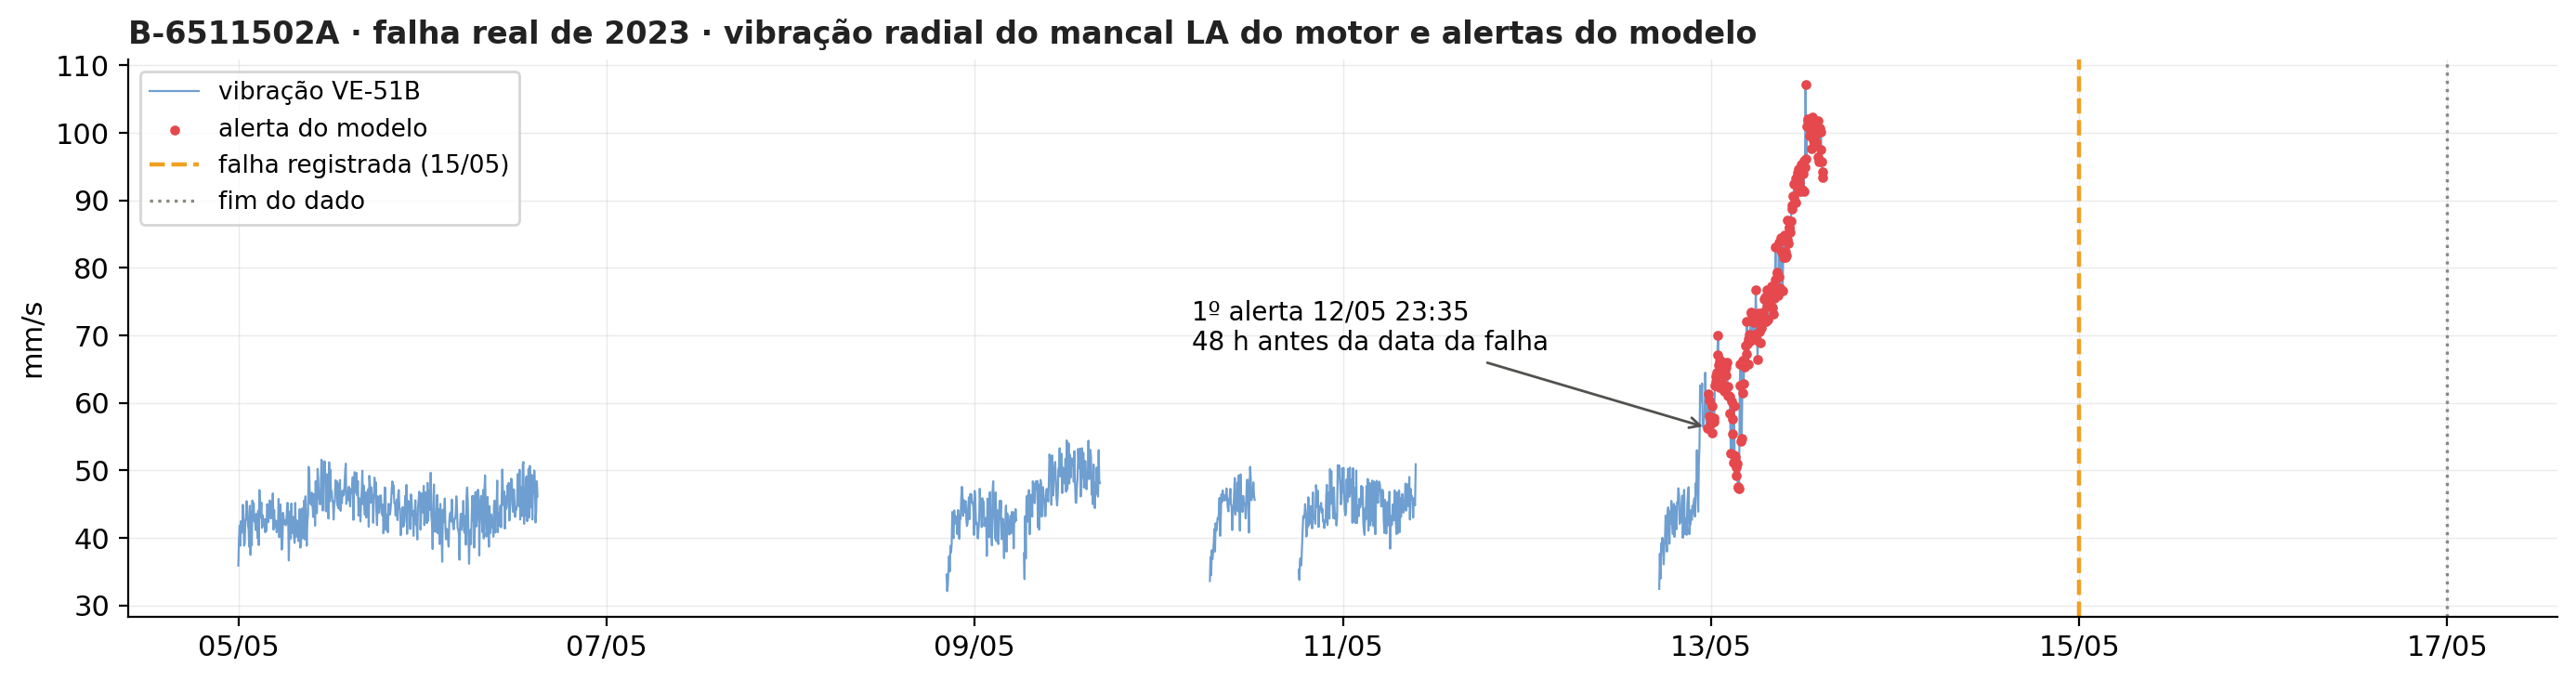

In [2]:
f = pd.read_parquet(R / "sem_mudanca/alerta_producao.parquet")["producao"]
ini = FALHA - pd.Timedelta(days=10)
v = operando(raw0.loc[ini:FALHA], SINAL)
a = f.loc[ini:FALHA]
fig, ax = plt.subplots(figsize=(14, 3.8))
ax.plot(v.index, v.values, color=SERIE, lw=0.8, label="vibração VE-51B")
p = v.reindex(a.index)[a]; ax.scatter(p.index, p.values, color=VERMELHO, s=8, zorder=3, label="alerta do modelo")
ax.axvline(FALHA, color="#f0a020", ls="--", lw=1.6, label="falha registrada (15/05)")
ax.axvline(raw0.index.max(), color="#8a897f", ls=":", lw=1.2, label="fim do dado")
if a.any():
    t1 = a[a].index.min()
    ax.annotate(f"1º alerta {t1:%d/%m %H:%M}\n{(FALHA - t1).total_seconds() / 3600:.0f} h antes da data da falha", (t1, v.asof(t1)),
                xytext=(-200, 30), textcoords="offset points", fontsize=10, arrowprops=dict(arrowstyle="->", color=TEXTO))
ax.set_ylabel("mm/s"); ax.legend(fontsize=9.5, loc="upper left"); ax.xaxis.set_major_formatter(mdates.DateFormatter("%d/%m"))
estilo(ax, "B-6511502A · falha real de 2023 · vibração radial do mancal LA do motor e alertas do modelo")
fig.tight_layout()

## 2. As mudanças simuladas (a partir de 01/11/2022)

Inspiradas no que vimos no B-8802B e no B-4064A depois de reparos: um mancal que passa a trabalhar mais quente, uma
bomba que passa a vibrar mais e um ponto de operação diferente. Mediana diária do sensor alterado: em cinza o dado
real, em azul com a mudança.

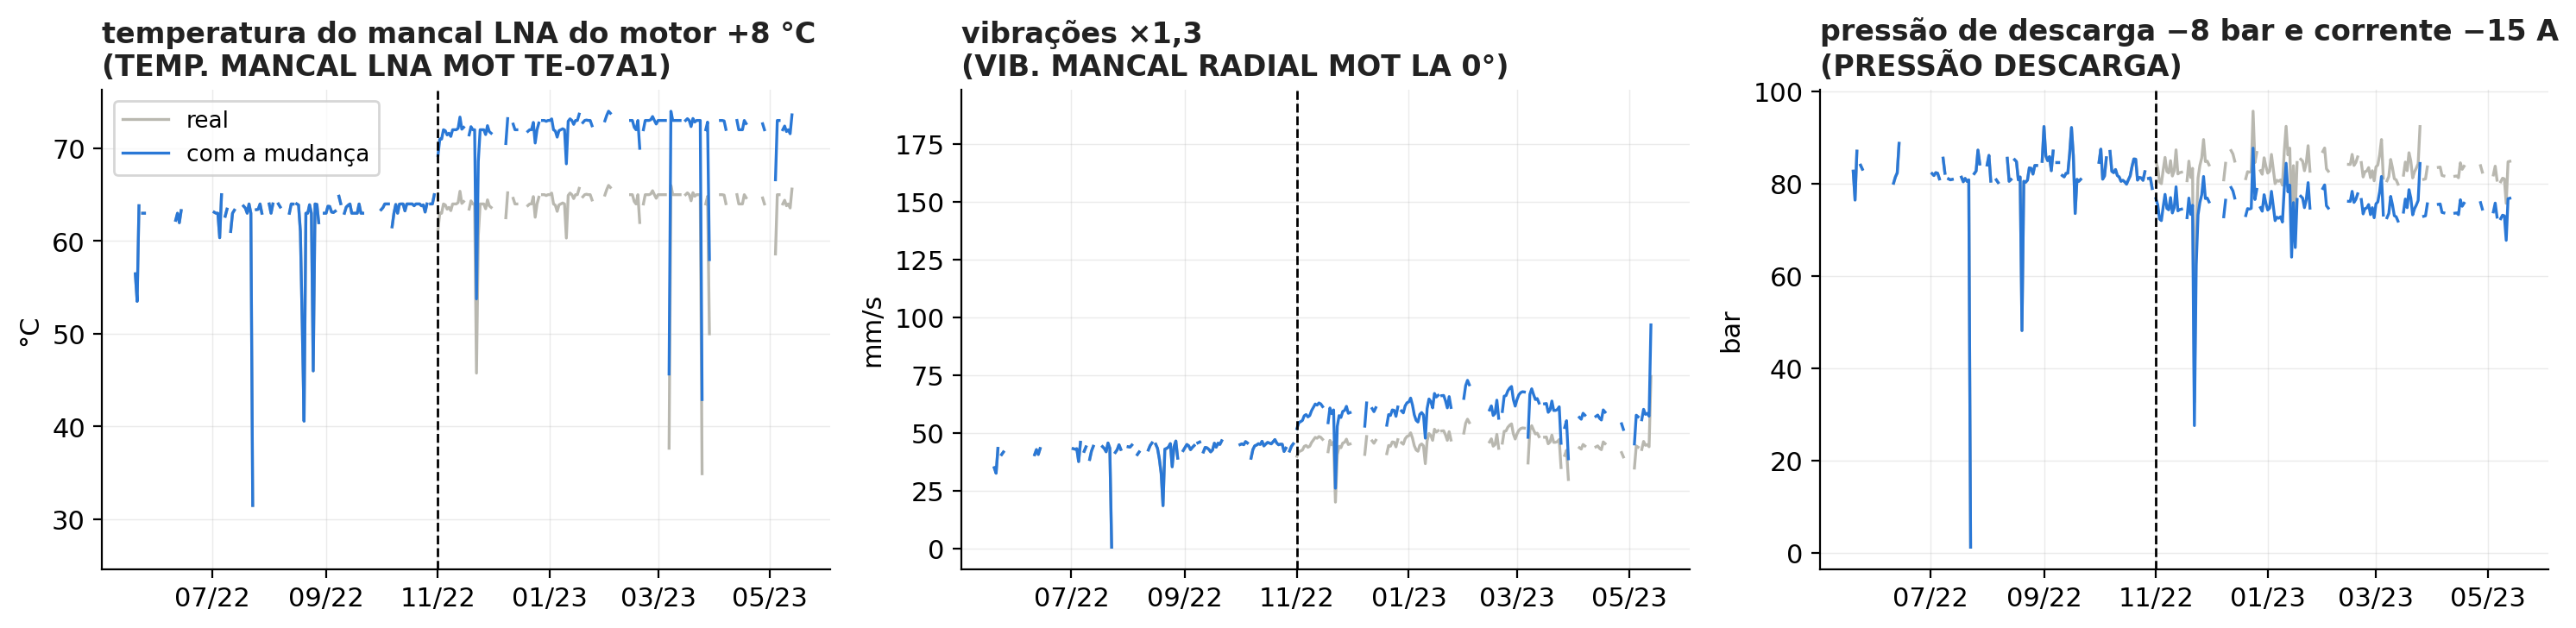

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for ax, (cen, (c, un)) in zip(axes, SENSOR_CEN.items()):
    raw = ds.aplicar(raw0, ds.CENARIOS[cen])
    d0 = operando(raw0, c).resample("1D").median(); d1 = operando(raw, c).resample("1D").median()
    ax.plot(d0.index, d0.values, color="#b9b8b0", lw=1.2, label="real")
    ax.plot(d1.index, d1.values, color="#2a78d6", lw=1.2, label="com a mudança")
    ax.axvline(MUD, color="black", ls="--", lw=1)
    ax.set_ylabel(un); ax.xaxis.set_major_formatter(mdates.DateFormatter("%m/%y"))
    estilo(ax, f"{NOMES[cen]}\n({c[:28]})")
axes[0].legend(fontsize=9.5)
fig.tight_layout()

## 3. Sem retreino: o modelo atual diante de cada mudança

Fração do tempo em alerta depois de 01/11/2022 (até uma semana antes da falha), com o modelo em produção.

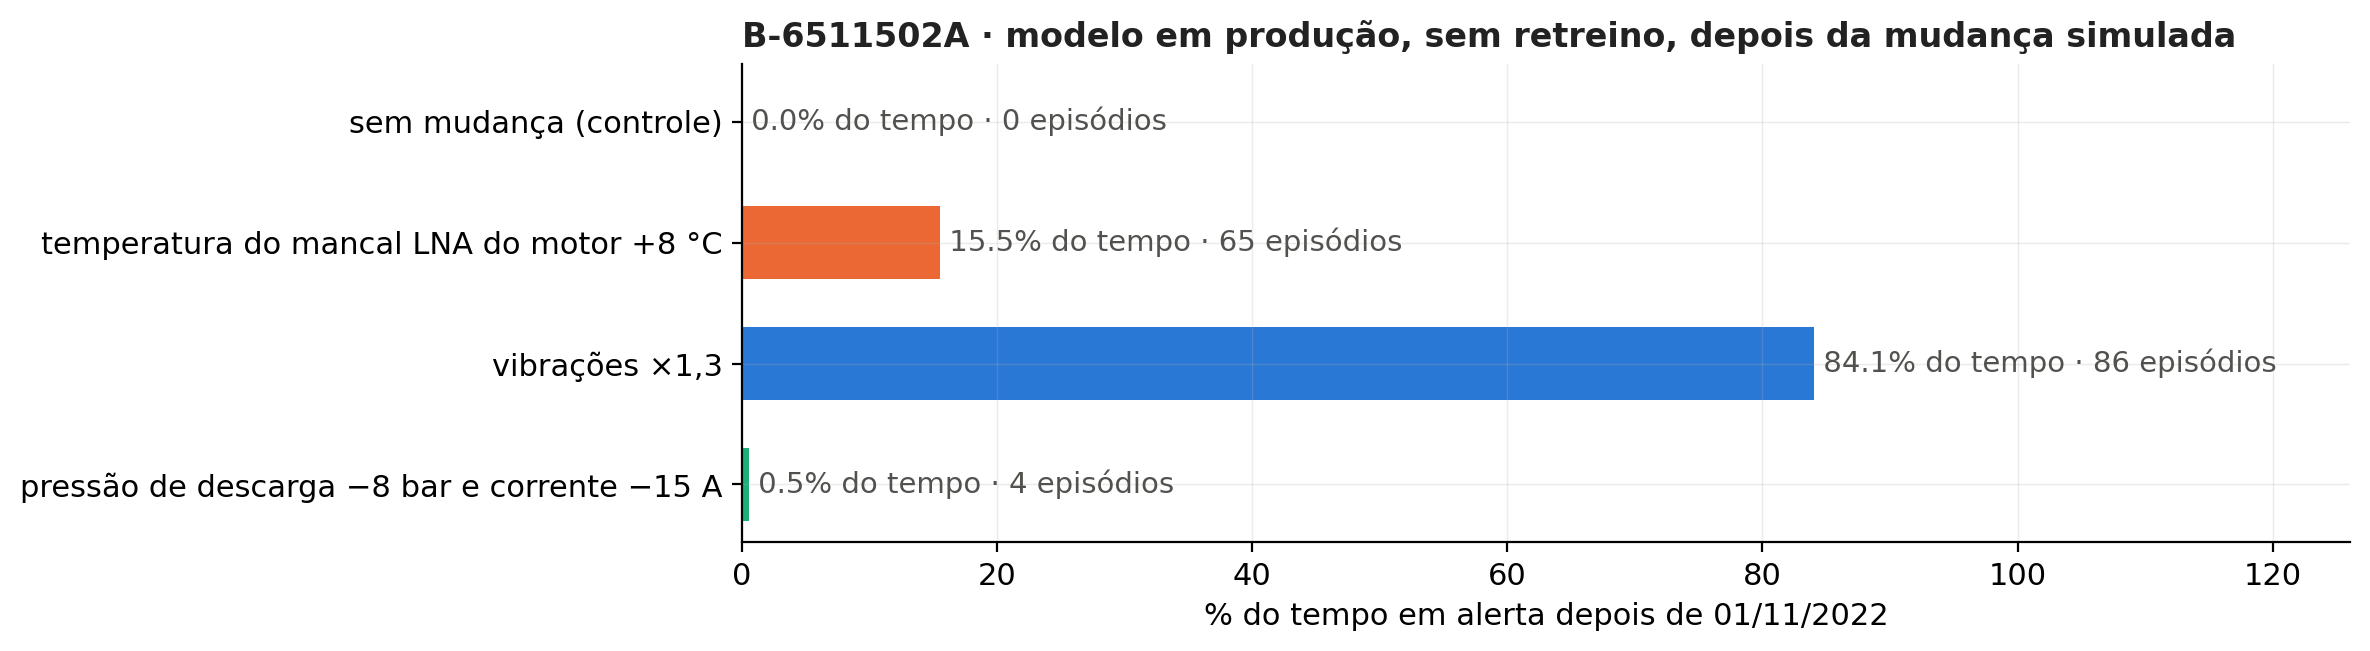

In [4]:
p = etapas[etapas.etapa == "produção (sem retreino)"].set_index("cenario")
p = p.reindex(["sem_mudanca", "temperatura", "vibracao", "regime"])
fig, ax = plt.subplots(figsize=(12, 3.4))
cores = ["#8a897f", "#eb6834", "#2a78d6", "#1baf7a"]
ax.barh(range(len(p)), p["alerta_pos_mudanca_%"], color=cores, height=0.6)
for i, (k, r) in enumerate(p.iterrows()):
    ax.text(r["alerta_pos_mudanca_%"], i, f" {r['alerta_pos_mudanca_%']:.1f}% do tempo · {int(r['episodios_pos_mudanca'])} episódios",
            va="center", fontsize=10.5, color=TEXTO)
ax.set_yticks(range(len(p)), ["sem mudança (controle)"] + [NOMES[c] for c in p.index[1:]]); ax.invert_yaxis()
ax.set_xlim(0, max(10, p["alerta_pos_mudanca_%"].max() * 1.5)); ax.set_xlabel("% do tempo em alerta depois de 01/11/2022")
estilo(ax, "B-6511502A · modelo em produção, sem retreino, depois da mudança simulada")
fig.tight_layout()

## 4. O ciclo de retreino

Para cada mudança: o sensor alterado, o modelo em operação em cada período (produção até o modelo de 1 mês entrar
em 01/12/2022; 3 meses em 01/02/2023; 6 meses em 01/05/2023), os alertas do modelo em operação e o dia em que o
monitor (KS diário) percebeu a mudança.

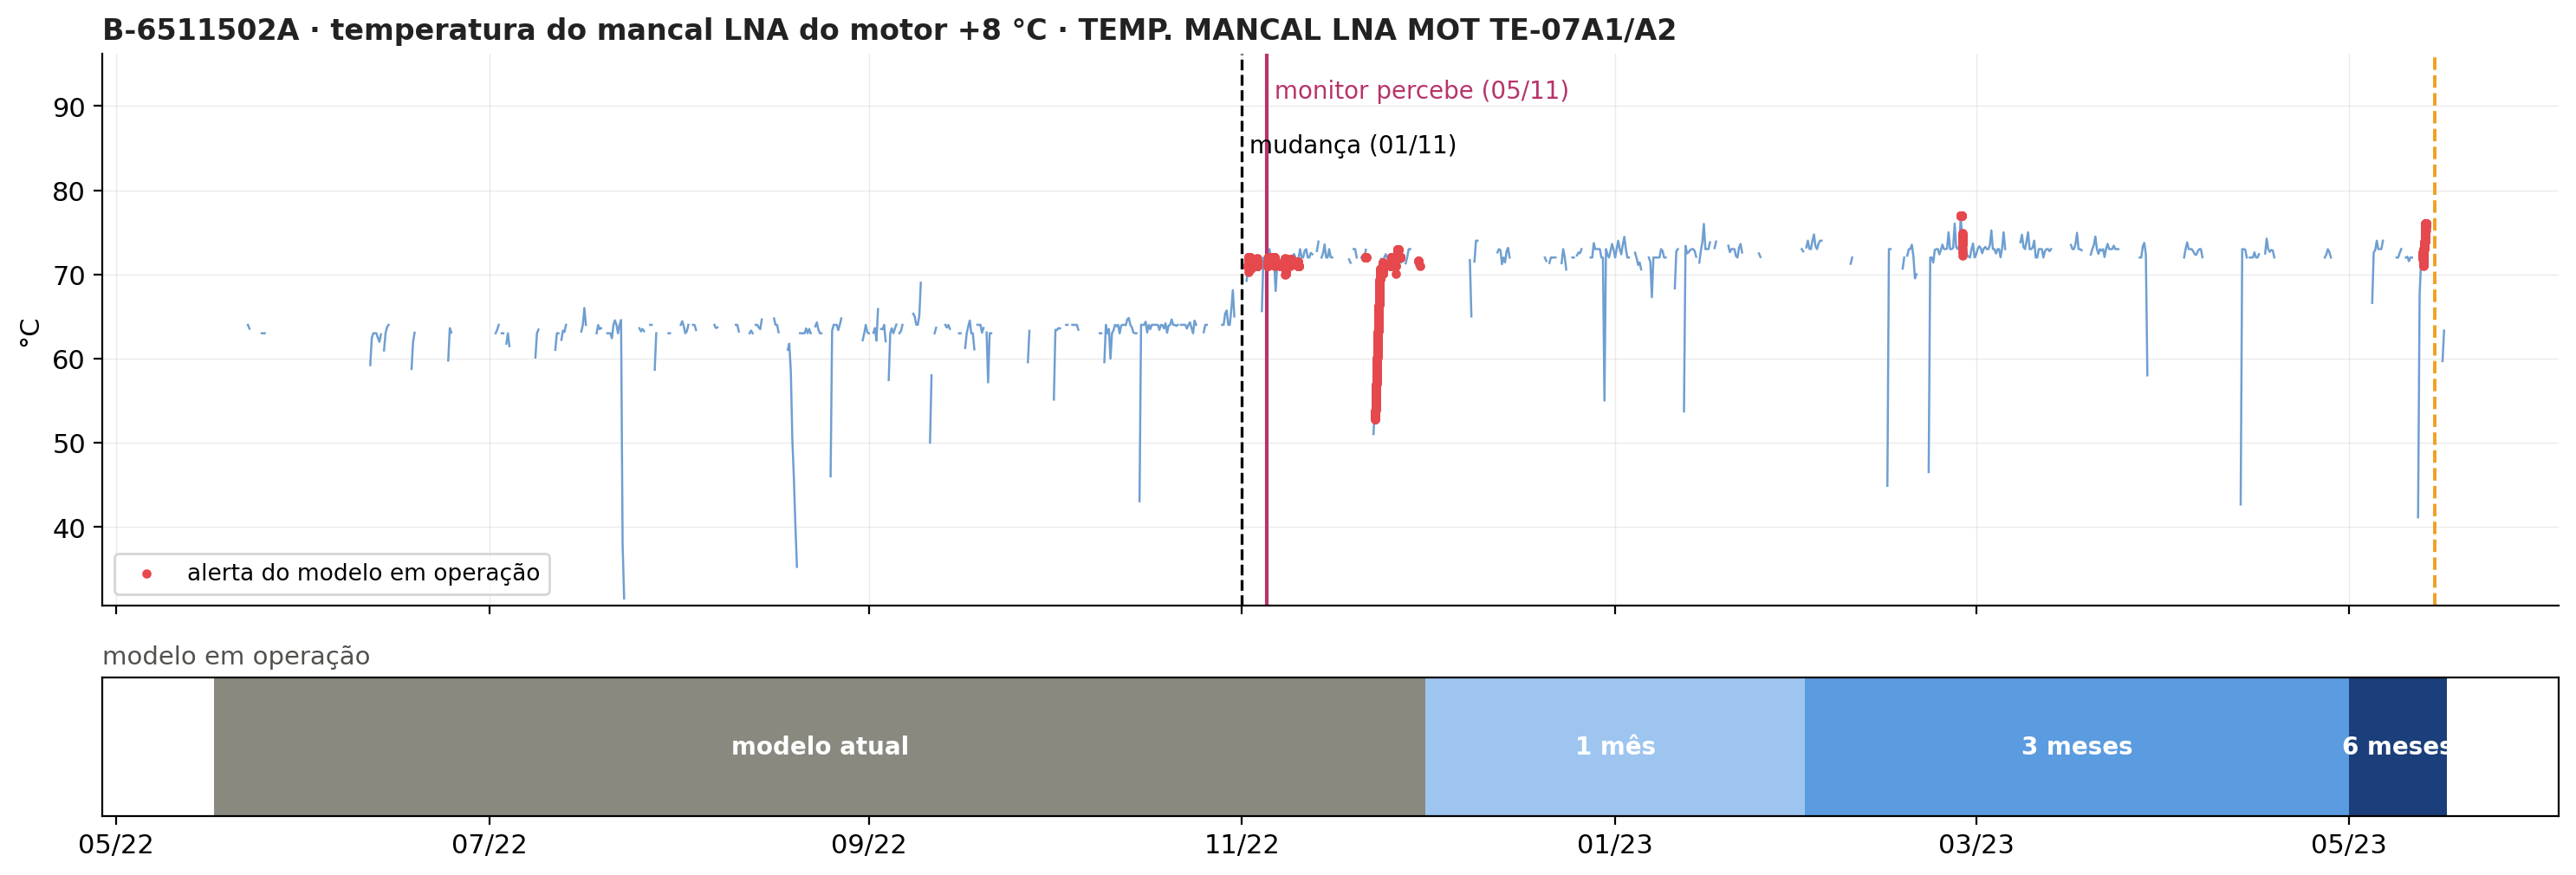

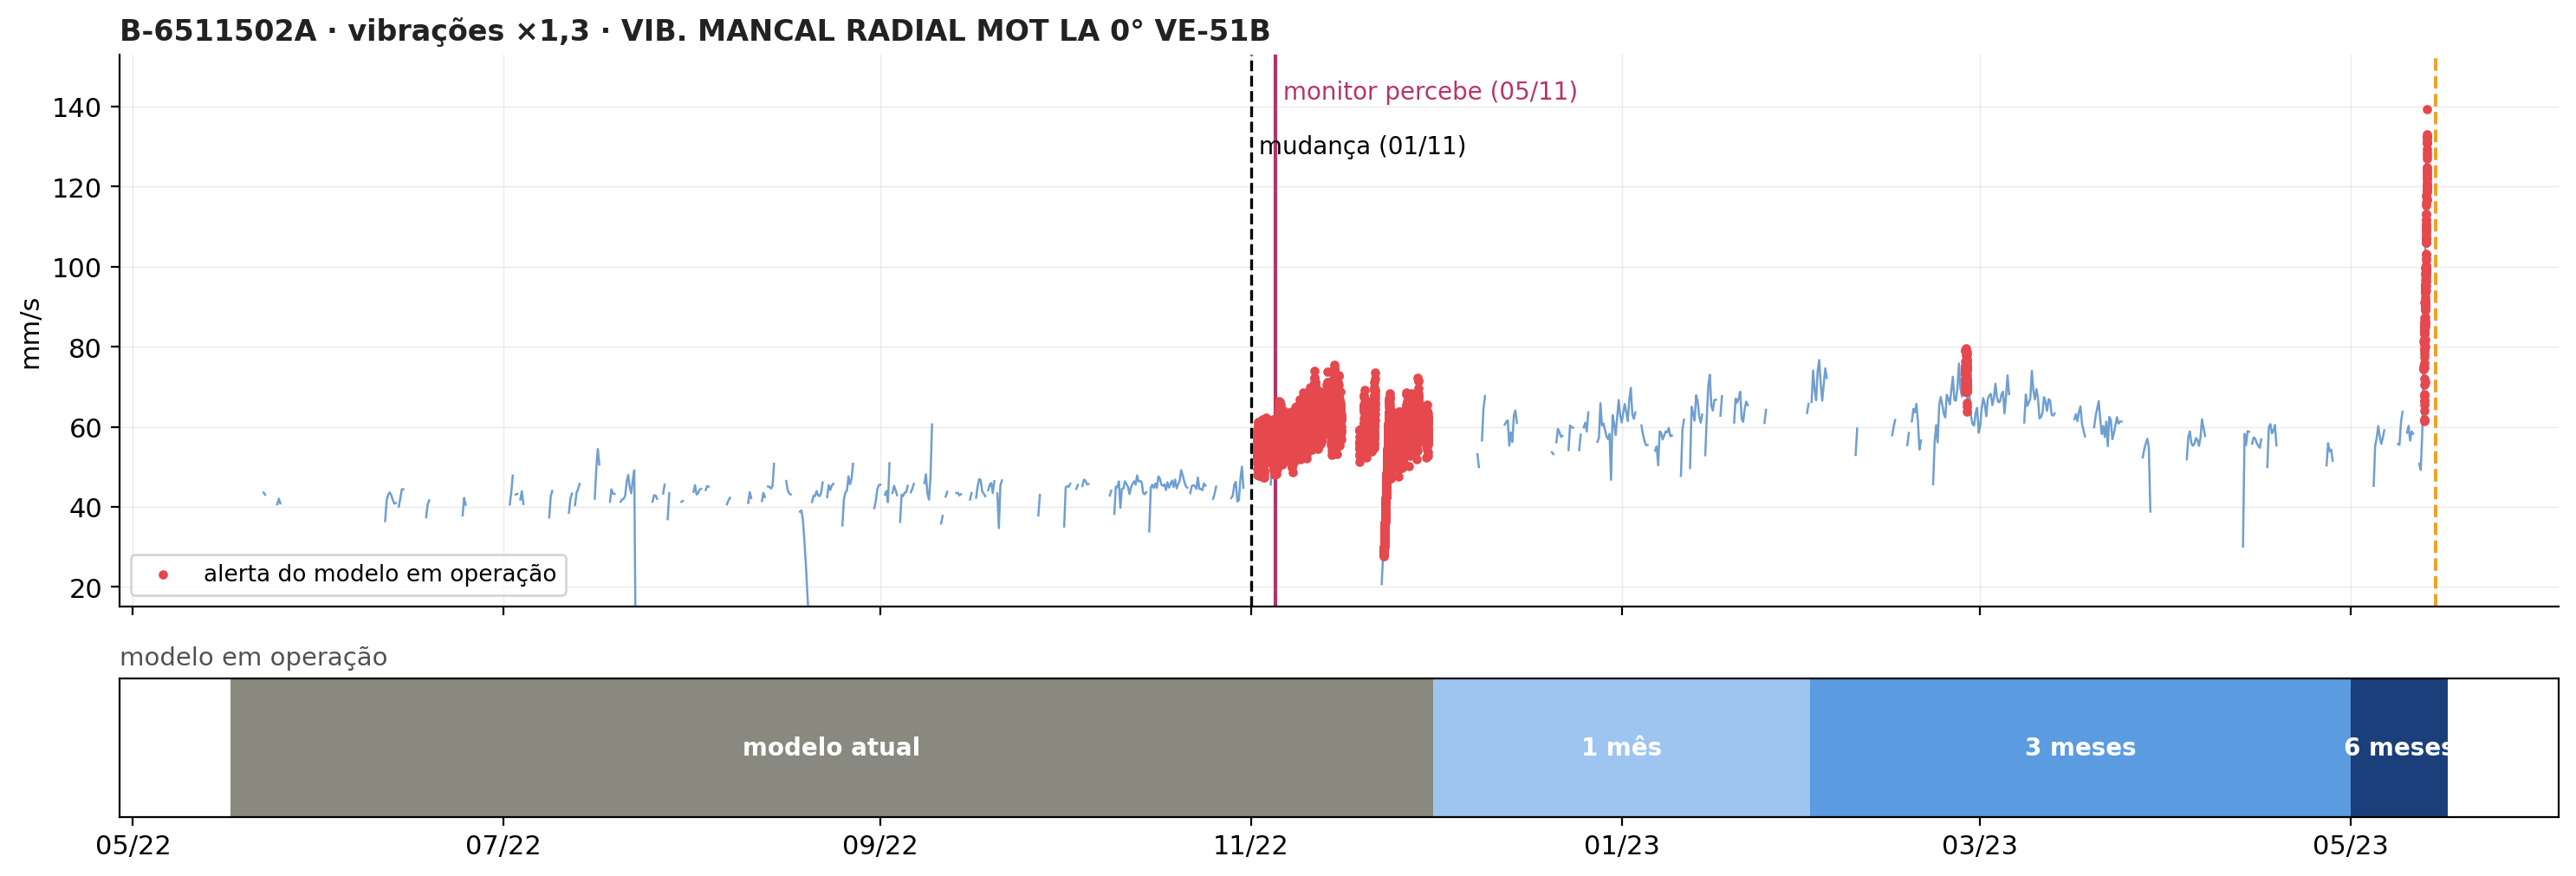

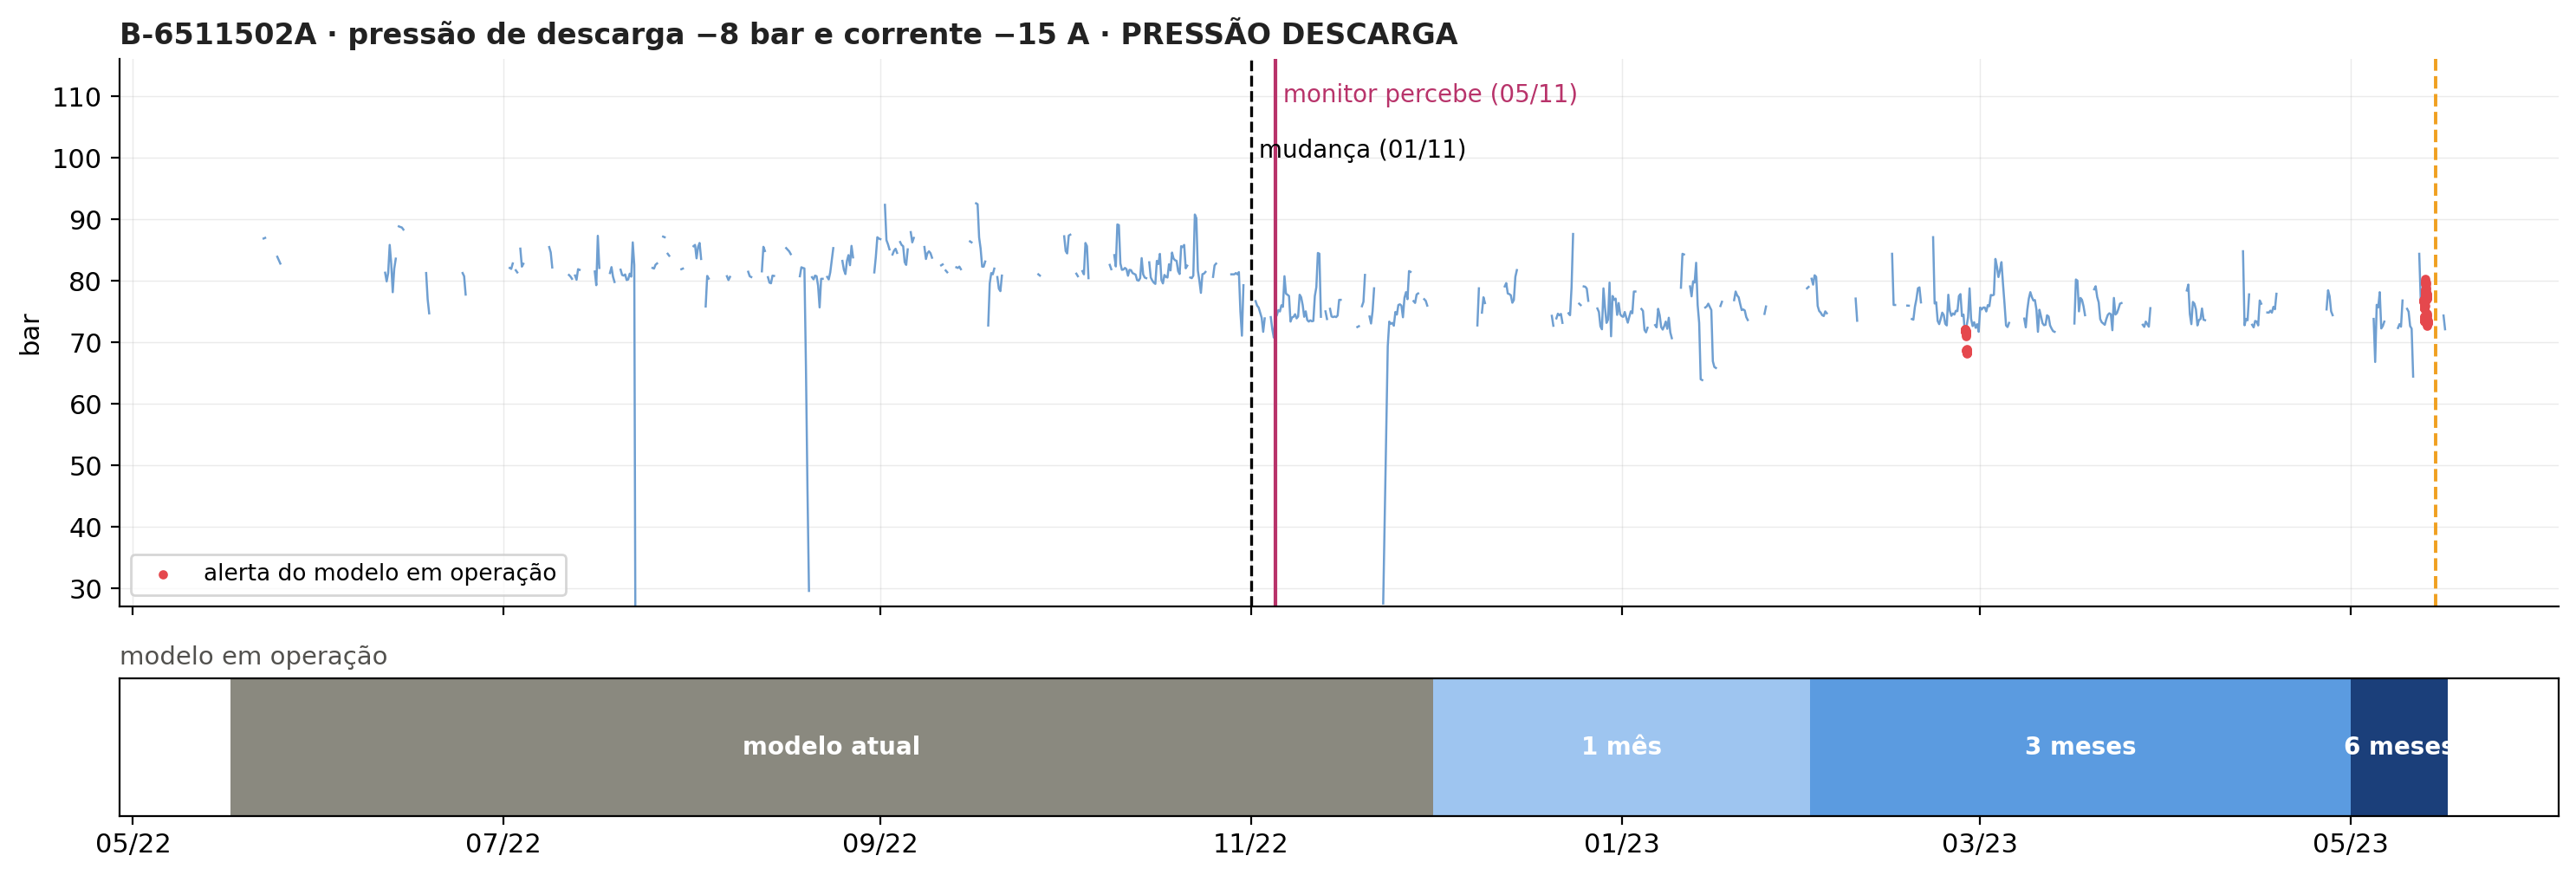

In [5]:
FASES = [("modelo atual", "alerta_producao", "#8a897f", pd.Timestamp("2022-05-17"), pd.Timestamp("2022-12-01")),
         ("1 mês", "alerta_m01", "#9ec5f0", pd.Timestamp("2022-12-01"), pd.Timestamp("2023-02-01")),
         ("3 meses", "alerta_m03", "#5b9be0", pd.Timestamp("2023-02-01"), pd.Timestamp("2023-05-01")),
         ("6 meses", "alerta_m06", "#1b3f7a", pd.Timestamp("2023-05-01"), raw0.index.max())]
def costurado(cen):
    partes = []
    for nome, arq, _, i, f in FASES:
        s = pd.read_parquet(R / cen / f"{arq}.parquet").iloc[:, 0]
        partes.append(s[(s.index >= i) & (s.index < f)])
    return pd.concat(partes).astype(bool)

for cen, (c, un) in SENSOR_CEN.items():
    raw = ds.aplicar(raw0, ds.CENARIOS[cen]); al = costurado(cen)
    fig, (a1, a2) = plt.subplots(2, 1, figsize=(15, 5.2), sharex=True, gridspec_kw={"height_ratios": [2.4, 0.6]})
    v = operando(raw, c); vm = v.resample("6h").median()
    a1.plot(vm.index, vm.values, color=SERIE, lw=0.9)
    p = v.reindex(al.index)[al]; a1.scatter(p.index, p.values, color=VERMELHO, s=8, zorder=3, label="alerta do modelo em operação")
    a1.axvline(MUD, color="black", ls="--", lw=1.2); a1.text(MUD, 0.82, " mudança (01/11)", transform=a1.get_xaxis_transform(), fontsize=10)
    a1.set_ylim(float(np.nanpercentile(vm, 0.5)) * 0.8, float(np.nanpercentile(v, 99.9)) * 1.25)
    det = etapas[(etapas.cenario == cen) & (etapas.etapa == "produção (sem retreino)")]["m6_primeiro_disparo"].iloc[0]
    if isinstance(det, str):
        a1.axvline(pd.Timestamp(det), color="#b8336a", lw=1.5)
        a1.text(pd.Timestamp(det), 0.92, f" monitor percebe ({pd.Timestamp(det):%d/%m})", transform=a1.get_xaxis_transform(),
                fontsize=10, color="#b8336a")
    a1.axvline(FALHA, color="#f0a020", ls="--", lw=1.4)
    a1.set_ylabel(un); a1.legend(fontsize=9.5, loc="lower left")
    estilo(a1, f"B-6511502A · {NOMES[cen]} · {c}")
    for nome, _, cor, i, f in FASES:
        a2.axvspan(i, f, color=cor, lw=0); a2.text(i + (f - i) / 2, 0.5, nome, ha="center", va="center", color="white", fontsize=10, fontweight="bold")
    a2.set_yticks([]); a2.set_ylim(0, 1); a2.xaxis.set_major_formatter(mdates.DateFormatter("%m/%y"))
    a2.set_title("modelo em operação", loc="left", fontsize=10.5, color=TEXTO)
    fig.tight_layout(); plt.show()

In [6]:
t = etapas[etapas.cenario != "sem_mudanca"].copy()
t["cenário"] = t.cenario.map(NOMES)
t["alerta no período (%)"] = t["alerta_pos_mudanca_%"].round(2)
t["falha real (h antes)"] = t["falha_antecedencia_h"].map(lambda v: "não detecta" if pd.isna(v) else f"{v:.0f}")
t["candidatos que detectam a falha"] = t["candidatos_que_detectam_falha"].map(lambda v: "" if pd.isna(v) else f"{int(v)}/12")
t["monitor: 1º disparo"] = t["m6_primeiro_disparo"].fillna("—")
t[["cenário", "etapa", "treino", "alerta no período (%)", "falha real (h antes)", "candidatos que detectam a falha",
   "monitor: 1º disparo"]].set_index(["cenário", "etapa"])

treino  \
cenário                                     etapa                                              
temperatura do mancal LNA do motor +8 °C    produção (sem retreino)  2022-05-20 → 2023-04-17   
                                            1 mês                    2022-11-01 → 2022-12-01   
                                            3 meses                  2022-11-01 → 2023-02-01   
                                            6 meses                  2022-11-01 → 2023-05-01   
vibrações ×1,3                              produção (sem retreino)  2022-05-20 → 2023-04-17   
                                            1 mês                    2022-11-01 → 2022-12-01   
                                            3 meses                  2022-11-01 → 2023-02-01   
                                            6 meses                  2022-11-01 → 2023-05-01   
pressão de descarga −8 bar e corrente −15 A produção (sem retreino)  2022-05-20 → 2023-04-17   
                                            1 mês                    2022-11-01 → 2022-12-01   
                                            3 meses                  2022-11-01 → 2023-02-01   
                                            6 meses                  2022-11-01 → 2023-05-01   

                                                                     alerta no período (%)  \
cenário                                     etapa                                            
temperatura do mancal LNA do motor +8 °C    produção (sem retreino)                  15.52   
                                            1 mês                                     0.00   
                                            3 meses                                   0.60   
                                            6 meses                                   0.00   
vibrações ×1,3                              produção (sem retreino)                  84.06   
                                            1 mês                                     0.00   
                                            3 meses                                   0.60   
                                            6 meses                                   0.00   
pressão de descarga −8 bar e corrente −15 A produção (sem retreino)                   0.52   
                                            1 mês                                     0.00   
                                            3 meses                                   0.65   
                                            6 meses                                   0.00   

                                                                    falha real (h antes)  \
cenário                                     etapa                                          
temperatura do mancal LNA do motor +8 °C    produção (sem retreino)                  110   
                                            1 mês                                     48   
                                            3 meses                                   48   
                                            6 meses                                   48   
vibrações ×1,3                              produção (sem retreino)                  110   
                                            1 mês                                     48   
                                            3 meses                                   48   
                                            6 meses                                   48   
pressão de descarga −8 bar e corrente −15 A produção (sem retreino)                  110   
                                            1 mês                                     48   
                                            3 meses                                   48   
                                            6 meses                                   48   

                                                                    candidatos que detectam a falha  \
cenário                         

## 5. A falha real com o modelo que estaria em operação

Em maio/2023 o modelo em operação seria o de 6 meses (treinado com nov/22–abr/23 já com a mudança). A falha real
recebe a mesma mudança (o normal novo continua valendo durante a falha). Vibração VE-51B e alertas, nos 10 dias antes:

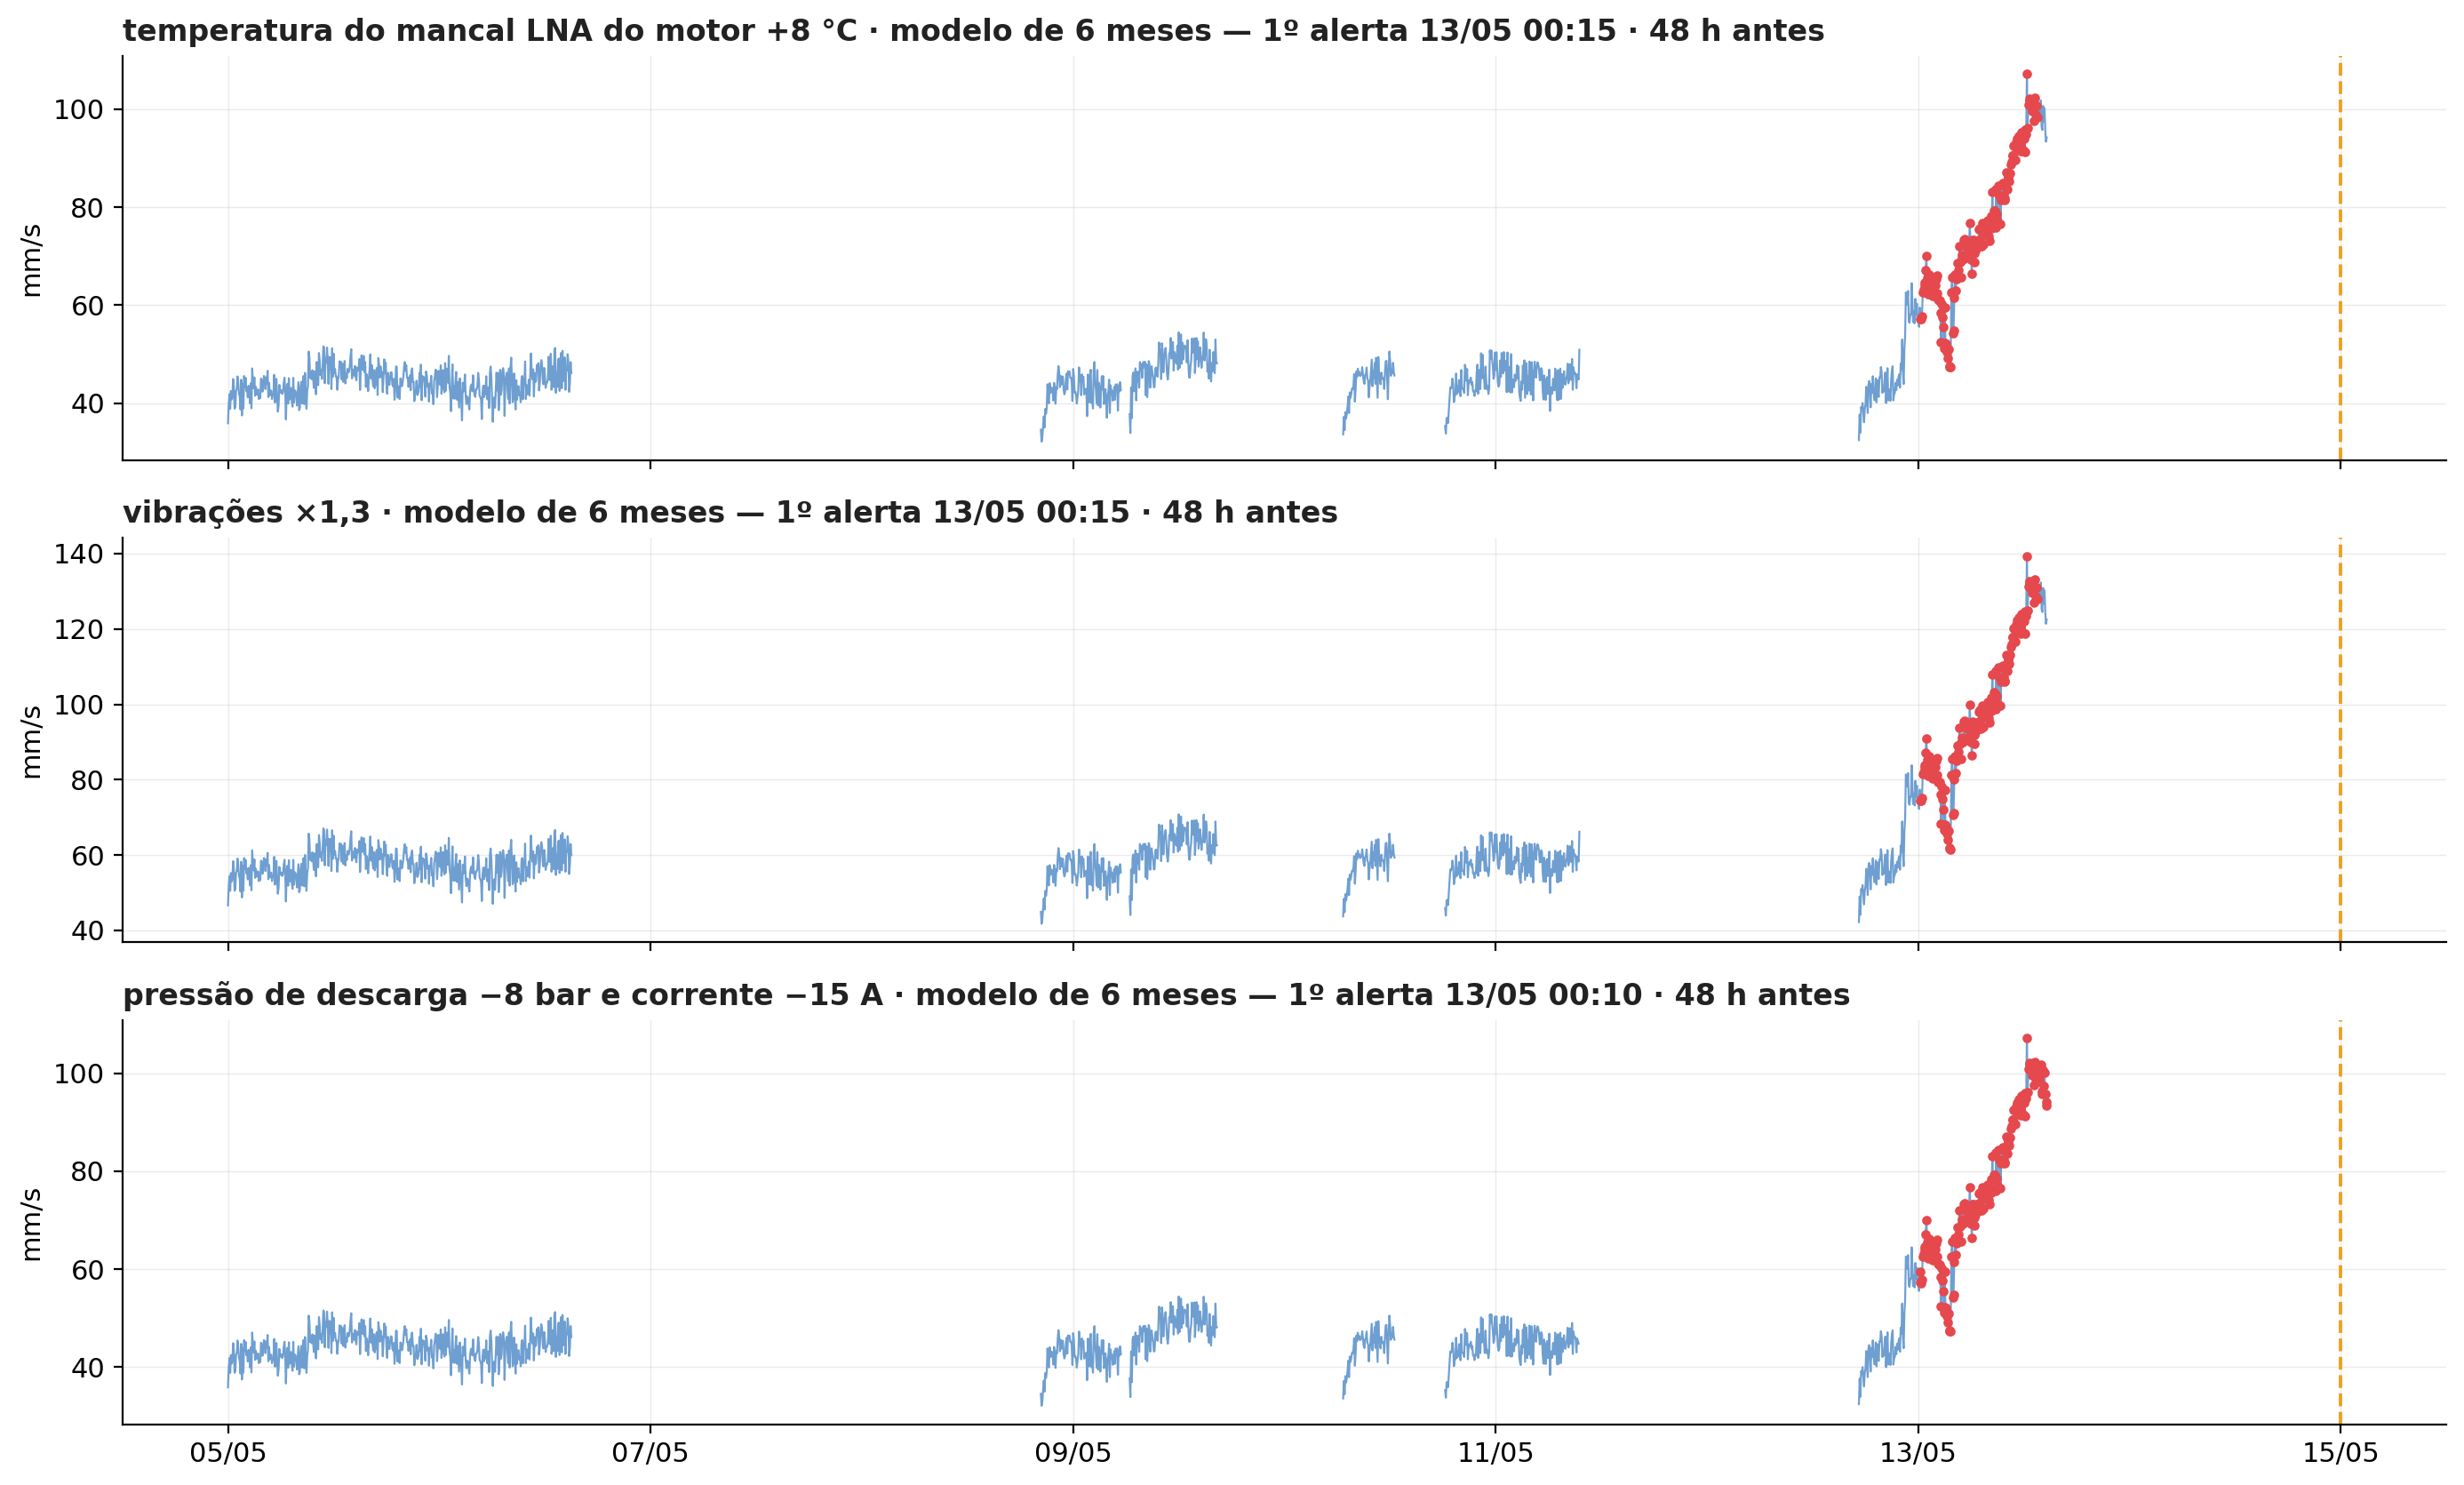

In [7]:
fig, axes = plt.subplots(3, 1, figsize=(14, 8.5), sharex=True)
ini = FALHA - pd.Timedelta(days=10)
for ax, cen in zip(axes, SENSOR_CEN):
    raw = ds.aplicar(raw0, ds.CENARIOS[cen])
    a = pd.read_parquet(R / cen / "alerta_m06.parquet").iloc[:, 0].astype(bool).loc[ini:FALHA]
    v = operando(raw.loc[ini:FALHA], SINAL)
    ax.plot(v.index, v.values, color=SERIE, lw=0.8)
    p = v.reindex(a.index)[a]; ax.scatter(p.index, p.values, color=VERMELHO, s=8, zorder=3)
    ax.axvline(FALHA, color="#f0a020", ls="--", lw=1.4)
    t1 = a[a].index.min() if a.any() else None
    txt = f"1º alerta {t1:%d/%m %H:%M} · {(FALHA - t1).total_seconds() / 3600:.0f} h antes" if t1 is not None else "não alerta"
    estilo(ax, f"{NOMES[cen]} · modelo de 6 meses — {txt}"); ax.set_ylabel("mm/s")
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%d/%m"))
fig.tight_layout()

## Conclusões

**Sem retreino, uma mudança de regime quebra o modelo atual.** Com o mancal 8 °C mais quente ele fica 15% do tempo em
alerta (65 episódios); com a vibração 30% mais alta, 84% do tempo. Só a mudança de ponto de operação (pressão e
corrente) ele absorve (0,5%), porque o treino já cobria uma faixa larga de operação.

**O monitor percebe a mudança em 4 dias** (05/11/2022) nos três cenários. No controle, sem mudança, ele também dispara
em 29/11/2022: a referência dele aqui tem só 6 meses (mai–out/2022) e estranha a estação — a mesma lição do B-8802B:
a referência do monitor precisa cobrir 12 meses. Por isso o aviso do monitor sempre passa pela confirmação da operação.

**O ciclo de retreino resolve.** Os modelos de 1, 3 e 6 meses, treinados com o dado depois da mudança, voltam a ~0% de
alerta, e **todos detectam a falha real de 15/05/2023 ~48 h antes**, como o modelo atual faz sem mudança — em cada etapa,
11 ou 12 dos 12 candidatos detectam. O único alerta deles no período normal (26/02/2023, nos três cenários) vem do dado
real, não da mudança simulada: vale olhar o que houve na bomba nesse dia.

**O que fica pronto para quando os dados de 2024–26 chegarem:** rodar o modelo atual neles (passo 1); se ele alarmar
muito, o monitor indica a mudança, a operação confirma e o ciclo de 1, 3, 6 e 12 meses roda — o mesmo processo que este
teste mostrou funcionando no B-6511502A.

**Limites:** as mudanças são simuladas (degraus permanentes), o ciclo só chega a 6 meses (o dado acaba em 05/2023) e a
falha de 2023 é súbita (o sinal aparece no último dia), então "48 h" é o máximo que esse dado permite.